<a href="https://colab.research.google.com/github/jsmak/dl-framework/blob/main/06_mlp_regression/06_mlp_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PyTorch로 캘리포니아 집값 예측**
- Dataset과 DataLoader를 사용해 신경망을 배치 단위로 학습하기.

5강에서는 `loss.backward()` 안에서 일어나는 일을 NumPy로 직접 만들어 보았습니다.  
이번에는 데이터가 두 개뿐이던 섭씨·화씨 문제를 벗어나, **실제 데이터인 캘리포니아 주택 가격**으로 다층 퍼셉트론(MLP)을 학습합니다.

1. 데이터 전처리와 **텐서 변환** 흐름 이해
2. **Dataset**과 **DataLoader**를 활용한 미니배치 학습
3. **다층 퍼셉트론(MLP)** 설계와 파라미터 확인
4. 기울기 초기화, 순전파, 손실 계산, 역전파, 업데이트의 **학습 루프**
5. **학습 곡선**과 테스트 손실로 모델 평가 및 과적합 확인
6. **계산 그래프** 시각화


## **1. 실습 준비**

계산 그래프를 그리기 위해 `torchviz`를 설치합니다.   
방화벽 등으로 데이터를 내려받을 수 없는 주피터 노트북 환경에서는 이 셀의 `wget` 줄의 주석을 해제해 내려받거나,   
`cal_housing_py3.pkz`를 노트북과 같은 폴더에 직접 복사하세요. 그런 다음 다음 셀의 데이터 로드 줄을 바꿔 실행합니다.


In [1]:
%pip install -q torchviz
#!wget -q -nc https://raw.githubusercontent.com/jsmak/dl-framework/main/06_mlp_regression/cal_housing_py3.pkz

## **2. 라이브러리 임포트와 데이터 로드**

데이터는 캘리포니아 주택 가격(California Housing) 데이터셋입니다.
- 입력 특성: 8개 (소득 수준, 주택 연식, 방 개수 등)
- 예측 대상: 주택 가격

주석 처리된 줄의 `data_home='./'`는 현재 폴더의 파일을 읽으라는 뜻이고, `download_if_missing=False`는 파일이 없을 때 인터넷에서 내려받지 말라는 뜻입니다.


In [2]:
import numpy as np
import torch
import torch.nn as nn

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 재현성을 위한 시드
np.random.seed(42)
torch.manual_seed(42)

# 데이터 로드
housing = fetch_california_housing() # 방화벽 등으로 데이터를 받을 수 없으면 이 줄을 주석 처리하고 아래 줄을 실행하세요.
# housing = fetch_california_housing(data_home='./', download_if_missing=False) 

X = housing.data
y = housing.target.reshape(-1, 1)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("특성 이름:", housing.feature_names)

X shape: (20640, 8)
y shape: (20640, 1)
특성 이름: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


## **3. 데이터 전처리**

데이터를 학습용과 테스트용으로 나누고 텐서로 변환합니다.

> **포인트:** 입력 특성의 스케일이 크게 다르면 경사하강법이 잘 수렴하지 않으므로, 학습 전에 표준화(Standardization)를 합니다.  
> 표준화 기준은 학습 데이터에서만 구하고(`fit_transform`), 테스트 데이터에는 그 기준을 적용합니다(`transform`).


In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y,  test_size=0.2,  random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# PyTorch 텐서 변환
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)

y_train = torch.tensor(y_train, dtype=torch.float32)
y_test = torch.tensor(y_test, dtype=torch.float32)

print("학습 데이터:", X_train.shape, y_train.shape)
print("테스트 데이터:", X_test.shape, y_test.shape)

학습 데이터: torch.Size([16512, 8]) torch.Size([16512, 1])
테스트 데이터: torch.Size([4128, 8]) torch.Size([4128, 1])


## **4. Dataset과 DataLoader 만들기**

큰 데이터를 한 번에 학습하면 메모리와 계산 비용이 커지므로, 미니배치 단위로 나누어 학습합니다.

- `Dataset`: 전체 샘플 수(`__len__`)와 인덱스로 샘플 하나를 꺼내는 방법(`__getitem__`)을 정의
- `DataLoader`: 미니배치 생성, 셔플(`shuffle`), 병렬 로딩 제공

학습 데이터는 매 에폭 섞고(`shuffle=True`), 테스트 데이터는 섞을 필요가 없습니다.


In [4]:
from torch.utils.data import Dataset, DataLoader

class HousingDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_dataset = HousingDataset(X_train, y_train)
test_dataset = HousingDataset(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64,  shuffle=False)

print("학습 배치 수:", len(train_loader))

학습 배치 수: 258


## **5. MLP 모델 설계**

선형 층(`nn.Linear`)과 활성화 함수(`nn.ReLU`)를 결합해 다층 퍼셉트론을 정의합니다.   
입력 특성은 8개, 출력은 주택 가격 1개입니다.

`named_parameters()`로 층별 파라미터의 크기를 확인합니다.


In [5]:
class HousingMLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.fc1 = nn.Linear(8, 64)
        self.relu1 = nn.ReLU()

        self.fc2 = nn.Linear(64, 32)
        self.relu2 = nn.ReLU()
        self.fc3 = nn.Linear(32, 1)

    def forward(self, x):
        x = self.fc1(x)
        x = self.relu1(x)

        x = self.fc2(x)
        x = self.relu2(x)

        x = self.fc3(x)
        return x

model = HousingMLP()

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(),  lr=0.001)
print(model)

# 각 레이어의 파라미터(가중치 및 편향) 크기 출력
print("\n=== Model Parameters ===")
for name, param in model.named_parameters():
    print(f"Parameter: {name} | Shape: {param.shape} | Requires Grad: {param.requires_grad}")

HousingMLP(
  (fc1): Linear(in_features=8, out_features=64, bias=True)
  (relu1): ReLU()
  (fc2): Linear(in_features=64, out_features=32, bias=True)
  (relu2): ReLU()
  (fc3): Linear(in_features=32, out_features=1, bias=True)
)

=== Model Parameters ===
Parameter: fc1.weight | Shape: torch.Size([64, 8]) | Requires Grad: True
Parameter: fc1.bias | Shape: torch.Size([64]) | Requires Grad: True
Parameter: fc2.weight | Shape: torch.Size([32, 64]) | Requires Grad: True
Parameter: fc2.bias | Shape: torch.Size([32]) | Requires Grad: True
Parameter: fc3.weight | Shape: torch.Size([1, 32]) | Requires Grad: True
Parameter: fc3.bias | Shape: torch.Size([1]) | Requires Grad: True


## **6. 모델 학습**

에폭마다 전체 학습 데이터를 미니배치 단위로 학습하는 이중 반복문입니다.

학습할 때는 `model.train()`으로 **학습 모드**, 평가할 때는 `model.eval()`로 **평가 모드**로 전환합니다.   
지금 모델에서는 차이가 없지만 드롭아웃이나 배치 정규화는 모드에 따라 다르게 동작합니다.   
평가할 때는 기울기가 필요 없으므로 `torch.no_grad()` 안에서 계산합니다.

### 학습 루프 다섯 줄
1. `optimizer.zero_grad()` : 기울기 초기화
2. `model(X_batch)` : 순전파
3. `criterion(predictions, y_batch)` : 손실 계산
4. `loss.backward()` : 역전파
5. `optimizer.step()` : 파라미터 업데이트


In [6]:
epochs = 20
train_losses = []  # 에폭별 Train Loss를 저장할 리스트
test_losses = []   # 에폭별 Test Loss를 저장할 리스트

for epoch in range(epochs):
    # --- Training ---
    model.train()
    total_loss = 0.0
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()                   # 1. 기존 기울기 초기화
        predictions = model(X_batch)            # 2. 순전파
        loss = criterion(predictions, y_batch)  # 3. 손실 계산
        loss.backward()                         # 4. 역전파
        optimizer.step()                        # 5. 파라미터 업데이트

        total_loss += loss.item() * len(X_batch)
    avg_loss = total_loss / len(train_dataset)
    train_losses.append(avg_loss)               # 에폭별 오차 기록

    # --- Evaluation (Test Loss) ---
    model.eval()
    total_test_loss = 0.0
    with torch.no_grad():
        for X_test_batch, y_test_batch in test_loader:
            test_preds = model(X_test_batch)
            test_loss = criterion(test_preds, y_test_batch)
            total_test_loss += test_loss.item() * len(X_test_batch)
    avg_test_loss = total_test_loss / len(test_dataset)
    test_losses.append(avg_test_loss)

    print(f"Epoch {epoch + 1:02d} | Train MSE: {avg_loss:.4f} | Test MSE: {avg_test_loss:.4f}")

Epoch 01 | Train MSE: 1.5014 | Test MSE: 0.6078
Epoch 02 | Train MSE: 0.4845 | Test MSE: 0.4456
Epoch 03 | Train MSE: 0.4118 | Test MSE: 0.4105
Epoch 04 | Train MSE: 0.3877 | Test MSE: 0.3913
Epoch 05 | Train MSE: 0.3710 | Test MSE: 0.3711
Epoch 06 | Train MSE: 0.3598 | Test MSE: 0.3639
Epoch 07 | Train MSE: 0.3484 | Test MSE: 0.3527
Epoch 08 | Train MSE: 0.3372 | Test MSE: 0.3410
Epoch 09 | Train MSE: 0.3310 | Test MSE: 0.3409
Epoch 10 | Train MSE: 0.3203 | Test MSE: 0.3244
Epoch 11 | Train MSE: 0.3176 | Test MSE: 0.3293
Epoch 12 | Train MSE: 0.3102 | Test MSE: 0.3149
Epoch 13 | Train MSE: 0.3060 | Test MSE: 0.3197
Epoch 14 | Train MSE: 0.3046 | Test MSE: 0.3218
Epoch 15 | Train MSE: 0.2991 | Test MSE: 0.3104
Epoch 16 | Train MSE: 0.2954 | Test MSE: 0.3395
Epoch 17 | Train MSE: 0.2944 | Test MSE: 0.3139
Epoch 18 | Train MSE: 0.2921 | Test MSE: 0.3071
Epoch 19 | Train MSE: 0.2936 | Test MSE: 0.2978
Epoch 20 | Train MSE: 0.2900 | Test MSE: 0.3051


## **7. 학습 곡선**

에폭별 학습 손실과 테스트 손실을 그립니다.   
두 손실이 함께 줄어드는지, 테스트 손실만 다시 올라가는 과적합이 있는지 확인합니다.


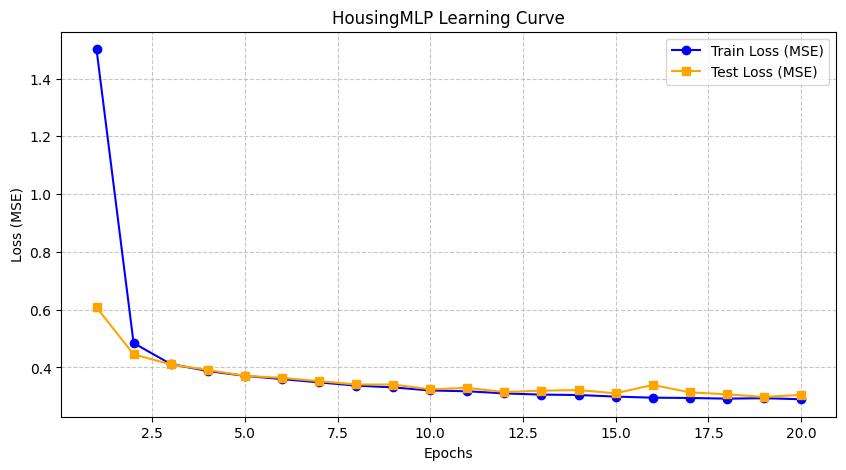

In [7]:
import matplotlib.pyplot as plt

# 학습 루프에서 기록한 train_losses와 test_losses로 학습 곡선 그리기
epochs_range = range(1, len(train_losses) + 1)

plt.figure(figsize=(10, 5))
plt.plot(epochs_range, train_losses, label='Train Loss (MSE)', color='blue', marker='o')
plt.plot(epochs_range, test_losses, label='Test Loss (MSE)', color='orange', marker='s')

plt.title('HousingMLP Learning Curve')
plt.xlabel('Epochs')
plt.ylabel('Loss (MSE)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

## **8. 최종 평가**

테스트 데이터로 MSE와 RMSE를 계산합니다.   
RMSE는 MSE의 제곱근으로, 예측 대상과 단위가 같아 해석하기 쉽습니다.


In [8]:
model.eval()
squared_error = 0.0

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        predictions = model(X_batch)
        squared_error += ((predictions - y_batch).square().sum().item())

test_mse = squared_error / len(test_dataset)
test_rmse = test_mse ** 0.5

print(f"Test MSE:  {test_mse:.4f}")
print(f"Test RMSE: {test_rmse:.4f}")

Test MSE:  0.3051
Test RMSE: 0.5524


## **9. 계산 그래프 출력**

학습이 끝난 모델로 순전파를 한 번 더 하고, 역전파 때 기울기가 전달되는 계산 그래프를 확인합니다. 
5강에서 직접 만든 것과 같은 구조입니다.

- 초록색: 손실 (출발점)
- 회색: 역전파 때 기울기를 전달하는 연산 노드
- 파란색: 학습할 파라미터 (도착점)


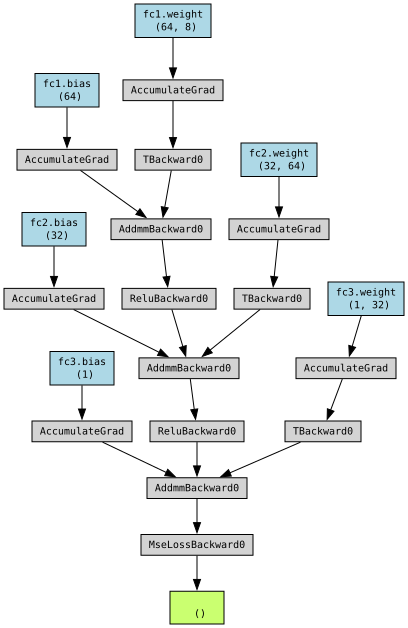

In [9]:
from torchviz import make_dot
from IPython.display import display, Image

# 학습된 모델의 파라미터를 이용해 새로운 계산 그래프 생성
model.eval()

X_batch, y_batch = next(iter(train_loader))

predictions = model(X_batch)
loss = criterion(predictions, y_batch)

# 손실에서 역방향으로 연결된 계산 그래프 시각화
dot = make_dot(
    loss,
    params=dict(model.named_parameters())
)

# 코랩 노트북에 표시
display(dot)